# Portfolio MV: MWIS e Pasqal 2D dai run salvati

Problema originale, incompatibilità, grafo MWIS, registro 2D, congruenza,
campionamento Pulser, selezione e allocazioni finali.

**Sola lettura:** 
Tutta la logica è importata da `qreduce.notebooks.portfolio_mv`.

In [10]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from qreduce.notebooks.portfolio_mv import (
    available_runs, comparison_summary, exact_diagnostic, find_repository_root,
    geometry_report, incompatibility_rows, load_run_view, plot_allocations, plot_incompatibilities,
    plot_mwis_graph, plot_pasqal_geometry, plot_sampling, run_summary,
    sampling_rows, sampling_summary,
)
from qreduce.notebooks.presentation import display_vertical

REPOSITORY_ROOT = find_repository_root()
OUTPUT_ROOT = REPOSITORY_ROOT / "outputs" / "portfolio_mv"
display(pd.DataFrame({"run_id_disponibili": available_runs(OUTPUT_ROOT)}))


,run_id_disponibili
0,portfolio_500_classic
1,portfolio_500_dwave
2,ptf_12_classic
3,ptf_12_pasqual


## 1. Selezione del run e del confronto

Cambiare gli ID qui, poi eseguire tutte le celle successive.
`BASELINE_RUN_ID = None` disabilita il confronto; `ROUND_INDEX` seleziona il
round nei run multi-round. I run devono essere già presenti in `OUTPUT_ROOT`.
La baseline non ha un grafo MWIS: il notebook non ne ricostruisce uno fittizio.


In [11]:
RUN_ID = "ptf_12_pasqual"
BASELINE_RUN_ID = "ptf_12_classic"  # None per analizzare solo RUN_ID
ROUND_INDEX = 0 #patrendo da 0
TOP_K = 20
EXACT_MAX_NODES = 16  # enumerazione diagnostica, solo per piccoli grafi

view = load_run_view(OUTPUT_ROOT, RUN_ID, ROUND_INDEX)
baseline = load_run_view(OUTPUT_ROOT, BASELINE_RUN_ID) if BASELINE_RUN_ID else None

display_vertical(run_summary(view), title="Run analizzato")
display_vertical(view.analysis.artifacts.experiment_metadata, title="Policy e generazione salvate")


Run analizzato


campo,valore
run_id,ptf_12_pasqual
stato,success
diagnostica,None
round,0
asset_originali,12
nodi_grafo,12
archi_grafo,5
asset_unione_candidati_MWIS,10
cap_dominio,7
asset_dominio_finale,7


Policy e generazione salvate


campo,valore
execution_mode,multi_round
generation_policy,"{\n ""alpha_base"": 0.05,\n ""alpha_spread"": 0.1,\n ""asset_count"": 12,\n ""beta_cluster_base"": 0.3,\n ""beta_cluster_spread"": 0.4,\n ""beta_market_base"": 0.8,\n ""beta_market_spread"": 0.4,\n ""cluster_count"": 2,\n ""cluster_factor_volatility"": 0.1,\n ""idiosyncratic_volatility"": 0.05,\n ""market_factor_volatility"": 0.15,\n ""min_observations_per_asset"": 10,\n ""observation_count"": 120,\n ""policy_id"": ""synthetic_factor_model"",\n ""policy_version"": ""1"",\n ""random_seed"": 42\n}"
portfolio_graph_policy,"{\n ""correlation_absolute_threshold"": 0.8,\n ""edge_mode"": ""near_duplicate"",\n ""near_duplicate_max_relative_return_difference"": 0.2,\n ""near_duplicate_max_relative_variance_difference"": 0.2,\n ""node_weight_formula_description"": ""max(expected_return_i, 0) / covariance_ii, normalized by global maximum"",\n ""node_weight_normalization"": ""divide_by_max"",\n ""node_weight_policy_id"": ""mean_variance_return_over_variance"",\n ""node_weight_policy_version"": ""1"",\n ""policy_id"": ""synthetic-portfolio-near_duplicate"",\n ""policy_version"": ""1""\n}"


## 2. Problema originale e correlazioni / incompatibilità

Le croci rosse indicano gli archi realmente persistiti nel round.
La sola correlazione sopra soglia non basta in modalità `near_duplicate`:
contano anche i criteri di somiglianza di rendimento e varianza.
Nei round successivi la matrice viene limitata ai nodi del round.


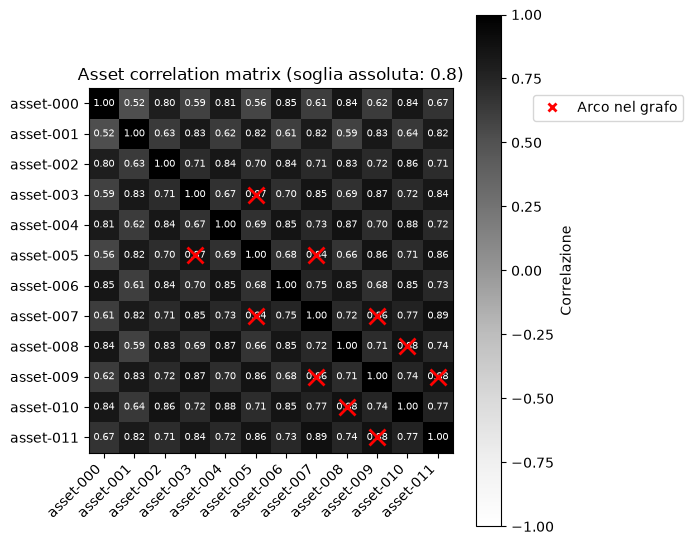

,asset_a,asset_b,motivo
0,asset-003,asset-005,edge_mode=near_duplicate; abs_correlation=0.86...
1,asset-005,asset-007,edge_mode=near_duplicate; abs_correlation=0.84...
2,asset-007,asset-009,edge_mode=near_duplicate; abs_correlation=0.85...
3,asset-008,asset-010,edge_mode=near_duplicate; abs_correlation=0.87...
4,asset-009,asset-011,edge_mode=near_duplicate; abs_correlation=0.87...


In [12]:
plot_incompatibilities(view)
plt.show()
display(pd.DataFrame(incompatibility_rows(view)))


## 3. Grafo MWIS logico e candidato selezionato

Il layout circolare è illustrativo, non fisico. Verde: unione dei candidati
scelti **prima del cap del dominio**. I pesi sui nodi sono score MWIS, non
allocazioni finanziarie. Quattro archi non significano automaticamente quattro
asset da escludere: archi con un estremo comune possono essere risolti insieme.


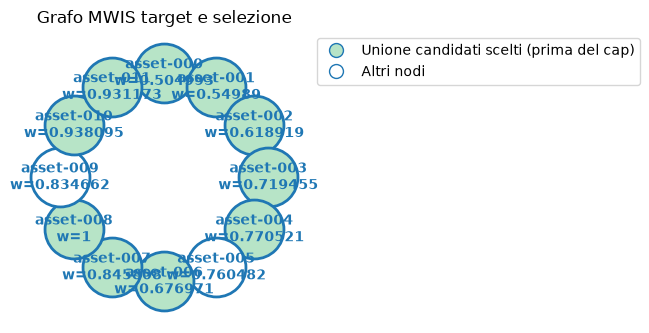

Ottimo MWIS esatto diagnostico (limite esplicito)


campo,valore
disponibile,True
node_order,"[""asset-000"", ""asset-001"", ""asset-002"", ""asset-003"", ""asset-004"", ""asset-005"", ""asset-006"", ""asset-007"", ""asset-008"", ""asset-009"", ""asset-010"", ""asset-011""]"
delta,"[1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1]"
qubo_energy,-6.61773
selection_weight,6.61773
is_independent_set,True
is_certified_qubo_optimum,True
is_certified_mwis_optimum,True
enumerated_assignment_count,4096
optimal_solution_count,1


In [13]:
plot_mwis_graph(view)
plt.show()
display_vertical(exact_diagnostic(view, EXACT_MAX_NODES), title="Ottimo MWIS esatto diagnostico (limite esplicito)")


## 4. Registro Pasqal 2D e congruenza dei grafi

Le coordinate sono quelle del job salvato. Gli archi geometrici vengono
ricalcolati usando il raggio registrato; sono evidenziati archi mancanti/extra.
**La soglia geometrica non annulla le interazioni fisiche sui non-archi.**
Baseline, presolve e compilazioni fallite possono non avere un registro.


Congruenza e diagnostiche fisiche registrate


campo,valore
disponibile,True
radius_um,10.0
coordinates,"{\n ""asset-000"": [\n -21.625321933960798,\n 19.21463916453795\n ],\n ""asset-001"": [\n -11.33915195097507,\n -26.404745421714658\n ],\n ""asset-002"": [\n 13.393709226762917,\n 25.11188607345148\n ],\n ""asset-003"": [\n -2.4988481020143265,\n -0.7568142981477295\n ],\n ""asset-004"": [\n 3.149170264886033,\n -19.27961342846595\n ],\n ""asset-005"": [\n -8.20556480325895,\n 3.9665187856775437\n ],\n ""asset-006"": [\n 12.99218678555132,\n -32.597012754625\n ],\n ""asset-007"": [\n -13.084445017495195,\n 8.313824090510508\n ],\n ""asset-008"": [\n 22.139680161635177,\n -5.748628086776817\n ],\n ""asset-009"": [\n -8.577532217899815,\n 15.8046186494778\n ],\n ""asset-010"": [\n 15.441594576585098,\n -7.253774223961091\n ],\n ""asset-011"": [\n -1.7854769898164013,\n 19.62910145003596\n ]\n}"
target_edges,"[[""asset-003"", ""asset-005""], [""asset-005"", ""asset-007""], [""asset-007"", ""asset-009""], [""asset-008"", ""asset-010""], [""asset-009"", ""asset-011""]]"
geometric_edges,"[[""asset-003"", ""asset-005""], [""asset-005"", ""asset-007""], [""asset-007"", ""asset-009""], [""asset-008"", ""asset-010""], [""asset-009"", ""asset-011""]]"
missing_edges,[]
extra_edges,[]
congruenti,True
coerente_con_archi_persistiti,True
geometry_diagnostics,"{\n ""c6_coefficient"": 865723.02,\n ""correct_edge_count"": 5,\n ""correct_non_edge_count"": 61,\n ""edge_non_edge_gap"": 6.184204709225882,\n ""fidelity_score"": 1.0,\n ""graph_edge_count"": 5,\n ""is_valid"": true,\n ""max_non_edge_interaction"": 0.3136182143885628,\n ""min_edge_interaction"": 1.9394792383207622,\n ""pair_count"": 66,\n ""pair_details"": [],\n ""provenance"": {\n ""node_count"": 12,\n ""threshold_method"": ""fixed""\n },\n ""spurious_interaction_count"": 0,\n ""threshold_used"": 0.9697396191603811,\n ""warnings"": [\n ""Small edge/non-edge gap (6.2x); distinguishing edges from non-edges may be unreliable""\n ],\n ""weak_edge_count"": 0\n}"


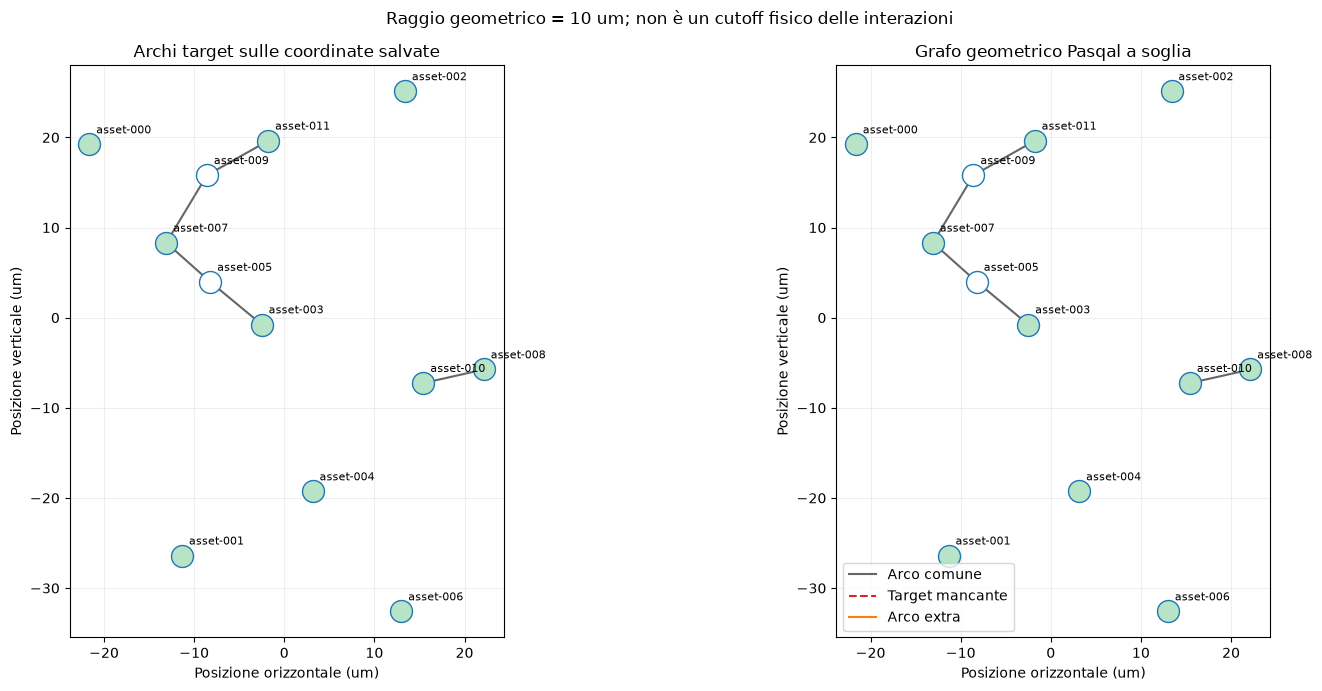

In [14]:
geometry = geometry_report(view)
display_vertical(geometry, title="Congruenza e diagnostiche fisiche registrate")
plot_pasqal_geometry(view)
plt.show()


## 5. Impulso e significato della verifica fisica

La congruenza geometrica e l'indipendenza dei minimi diagonali non certificano
l'evoluzione finita né l'ottimo pesato. `classical_ranking` significa che i pesi
sono valutati dopo il campionamento, non codificati fisicamente nell'impulso.
L'analisi riporta le diagnostiche salvate, senza rigenerare una sequenza.


In [15]:
display_vertical(view.payload.get("pulse_strategy") or {}, title="Strategia impulso")
display_vertical(view.payload.get("pulse_diagnostics") or {}, title="Diagnostica impulso")
display_vertical(view.payload.get("physical_vs_canonical") or {}, title="Minimi diagonali fisici vs ottimo MWIS")


Strategia impulso


campo,valore
additional_parameters,"{\n ""description"": ""Default smoothed annealing for MIS"",\n ""target_device"": ""AnalogDevice""\n}"
final_detuning_rad_per_us,0.96974
initial_detuning_rad_per_us,-10.0
max_amplitude_rad_per_us,10.0
ramp_down_fraction,0.15
ramp_up_fraction,0.15
strategy_id,smoothed_annealing
strategy_version,1
total_duration_ns,4000


Diagnostica impulso


campo,valore
adiabatic_ratio,40.0
amplitude_to_interaction_ratio,0.902623
detuning_range,10.96974
device_compatible,True
max_interaction_energy,11.078827
provenance,"{\n ""c6_coefficient"": 862690.0,\n ""min_distance_um"": 6.534717710681521\n}"
strategy_id,smoothed_annealing
strategy_version,1
total_duration_ns,4000
validation_message,None


Minimi diagonali fisici vs ottimo MWIS


campo,valore
all_ground_states_independent,True
all_ground_states_optimal,True
any_ground_state_optimal,True
canonical_optimum,"[1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1]"
canonical_optimum_energy,-8.227883
canonical_optimum_weight,6.61773
energy_gap_to_optimum,0.0
ground_state_matches_optimum,True
num_degenerate_ground_states,1
physical_ground_energy,-8.227883


## 6. Selezioni Pulser: distribuzione e rispetto degli archi

Bitstring nell'ordine dei nodi riportato sotto. Indipendenza e peso vengono
ricalcolati dai campioni raw. Il grafico mostra il top per frequenza, **non** il
ranking MWIS; le frequenze per asset usano tutte le occorrenze.
Il presolve produce un risultato deterministico: non sono shot Pulser.


Ordine bit: ('asset-000', 'asset-001', 'asset-002', 'asset-003', 'asset-004', 'asset-005', 'asset-006', 'asset-007', 'asset-008', 'asset-009', 'asset-010', 'asset-011')
Qualità del campionamento raw


campo,valore
bitstring_distinti,665
occorrenze_raw,1000
occorrenze_indipendenti,854
occorrenze_non_indipendenti,146
frazione_indipendente,0.854
nota,Campioni raw prima di repair/completamento.


,raw_sample_id,bitstring,occorrenze,indipendente,archi_violati,asset_selezionati,peso_MWIS,provider,backend
0,ptf_12_pasqual:round:0:pasqal-local:sample:0396,101010101000,9,True,0,5,3.571405,pasqal,pasqal_local
1,ptf_12_pasqual:round:0:pasqal-local:sample:0583,111010100000,8,True,0,5,3.121294,pasqal,pasqal_local
2,ptf_12_pasqual:round:0:pasqal-local:sample:0364,101000100010,7,True,0,4,2.738978,pasqal,pasqal_local
3,ptf_12_pasqual:round:0:pasqal-local:sample:0129,010000101000,6,True,0,3,2.226861,pasqal,pasqal_local
4,ptf_12_pasqual:round:0:pasqal-local:sample:0383,101010001000,6,True,0,4,2.894433,pasqal,pasqal_local
5,ptf_12_pasqual:round:0:pasqal-local:sample:0482,110010101000,6,True,0,5,3.502375,pasqal,pasqal_local
6,ptf_12_pasqual:round:0:pasqal-local:sample:0222,011010100000,5,True,0,4,2.616301,pasqal,pasqal_local
7,ptf_12_pasqual:round:0:pasqal-local:sample:0273,011110100000,5,True,0,5,3.335756,pasqal,pasqal_local
8,ptf_12_pasqual:round:0:pasqal-local:sample:0428,101110100000,5,True,0,5,3.290860,pasqal,pasqal_local
9,ptf_12_pasqual:round:0:pasqal-local:sample:0436,101110101100,5,True,0,7,5.125522,pasqal,pasqal_local


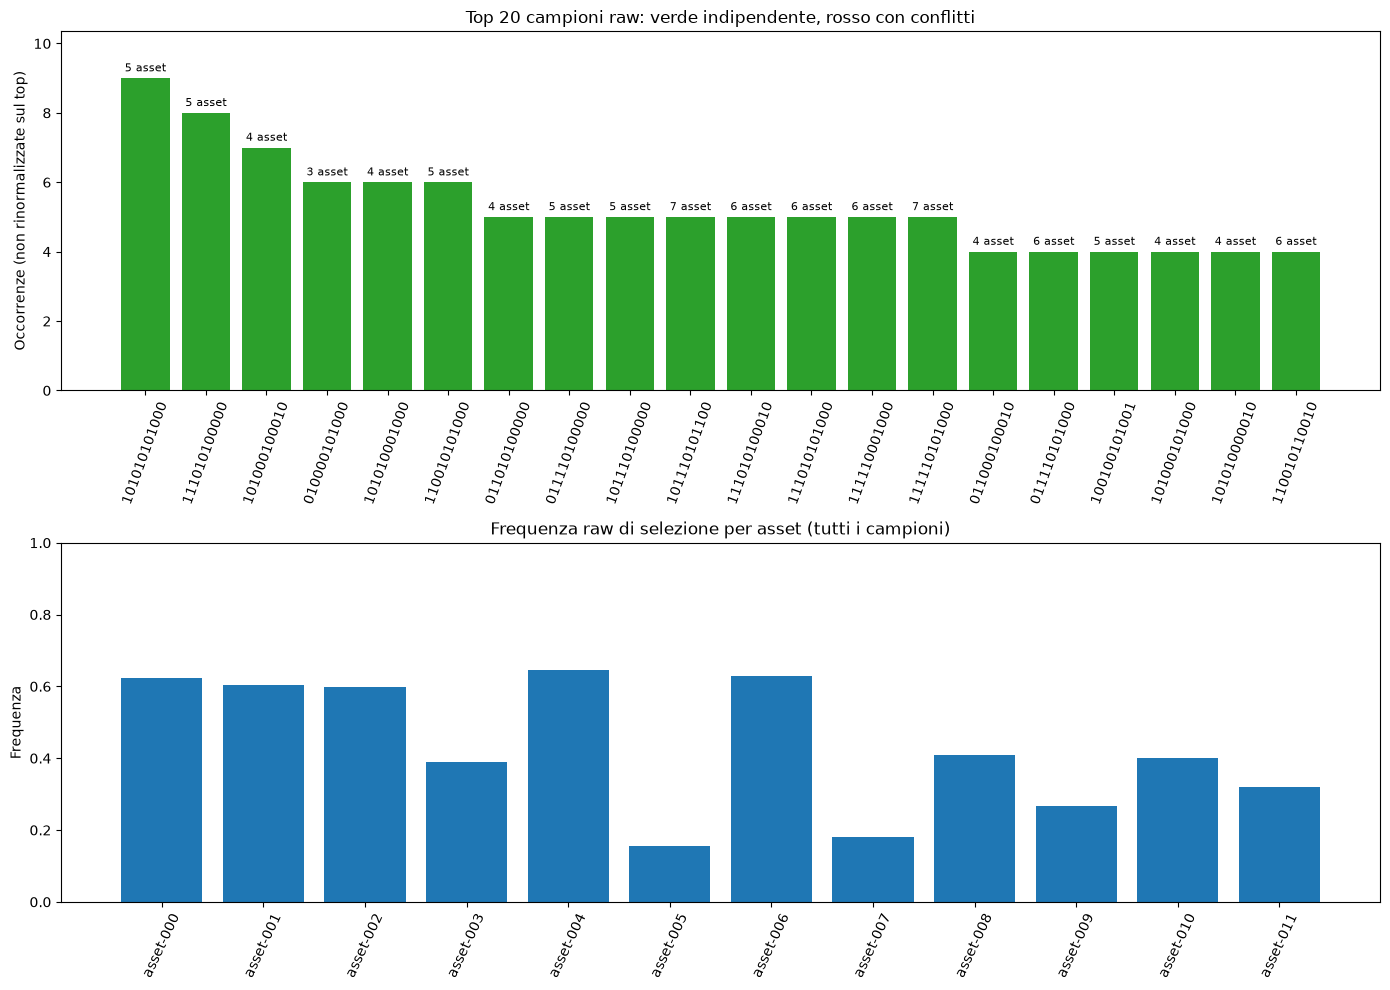

In [16]:
print("Ordine bit:", view.graph.node_ids if view.graph else "non disponibile")
display_vertical(sampling_summary(view), title="Qualità del campionamento raw")
display(pd.DataFrame(sampling_rows(view)).head(TOP_K))
plot_sampling(view, TOP_K)
plt.show()


## 7. Candidati scelti, repair, completamento e dominio finale

Le tre quantità sono distinte: nodi del candidato MWIS, asset conservati nel
dominio dopo il cap, asset effettivamente investiti dal solver residuo.
Le aggiunte classiche non sono misure Pulser. In presenza di più candidati,
il verde del grafo rappresenta la loro unione, non un singolo independent set.


In [17]:
display(pd.DataFrame(view.round_result.get("selected_mis_samples", [])))
display(pd.DataFrame(view.round_result.get("candidate_records", [])).query("selection_status == 'selected'") if view.round_result.get("candidate_records") else pd.DataFrame())
display(pd.DataFrame(view.round_result.get("candidate_domain_item_records", [])))
display(pd.DataFrame(view.analysis.solution_selection_rows()))


,backend_reported_score,backend_reported_score_kind,canonical_ising_energy,canonical_qubo_energy,delta,effective_compilation_parameters,effective_execution_parameters,execution_runtime_seconds,is_independent_set,node_order,num_selected,num_violated_edges,occurrence_count,raw_backend_metadata,raw_sample_id,selection_weight,source_backend_id,source_provider_id,source_raw_sample_ids,violated_edges
0,None,unavailable,-6.005935,-6.005935,"[1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1]",{},"{'pulse_strategy_id': 'smoothed_annealing', 's...",None,True,"[asset-000, asset-001, asset-002, asset-003, a...",8,0,1,{},ptf_12_pasqual:round:0:pasqal-local:sample:0438,6.005935,pasqal_local,pasqal,[ptf_12_pasqual:round:0:pasqal-local:sample:0438],[]
1,None,unavailable,-5.998811,-5.998811,"[1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1]",{},"{'pulse_strategy_id': 'smoothed_annealing', 's...",None,True,"[asset-000, asset-001, asset-002, asset-003, a...",8,0,2,{},ptf_12_pasqual:round:0:pasqal-local:sample:0537,5.998811,pasqal_local,pasqal,[ptf_12_pasqual:round:0:pasqal-local:sample:0537],[]


,candidate_id,candidate_rank_key,completed_delta,completion_actions,completion_applied,completion_policy_id,completion_runtime_seconds,energy_after_completion,energy_recomputed_after_repair,num_selected,...,raw_energy,raw_sample_id,rejection_reason,repair_actions,repair_status,repaired_delta,selected_item_ids,selection_status,selection_weight,source_raw_sample_ids
438,candidate:0438,"[-6.005935, -8, -6.005935, ptf_12_pasqual:roun...",None,[],False,None,None,None,None,8.0,...,-6.005935,ptf_12_pasqual:round:0:pasqal-local:sample:0438,NaN,[],valid_without_repair,"[1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1]","[asset-000, asset-002, asset-003, asset-004, a...",selected,6.005935,[ptf_12_pasqual:round:0:pasqal-local:sample:0438]
537,candidate:0537,"[-5.998811, -8, -5.998811, ptf_12_pasqual:roun...",None,[],False,None,None,None,None,8.0,...,-5.998811,ptf_12_pasqual:round:0:pasqal-local:sample:0537,NaN,[],valid_without_repair,"[1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1]","[asset-000, asset-001, asset-003, asset-004, a...",selected,5.998811,[ptf_12_pasqual:round:0:pasqal-local:sample:0537]


,decision,item_id,mean_candidate_quality,reason,selection_frequency
0,retained,asset-000,6.002373,selected_candidate_aggregation,2
1,excluded,asset-001,5.998811,candidate_domain_cap,1
2,excluded,asset-002,6.005935,candidate_domain_cap,1
3,retained,asset-003,6.002373,selected_candidate_aggregation,2
4,retained,asset-004,6.002373,selected_candidate_aggregation,2
5,excluded,asset-005,NaN,not_present_in_selected_candidates,0
6,retained,asset-006,6.002373,selected_candidate_aggregation,2
7,retained,asset-007,6.002373,selected_candidate_aggregation,2
8,excluded,asset-008,5.998811,candidate_domain_cap,1
9,excluded,asset-009,NaN,not_present_in_selected_candidates,0


,asset,retained,selected,invested,delta,weight,valid
0,asset-000,True,False,False,0.0,0.0,True
1,asset-001,False,False,False,0.0,0.0,True
2,asset-002,False,False,False,0.0,0.0,True
3,asset-003,True,True,True,1.0,0.2,True
4,asset-004,True,False,False,0.0,0.0,True
5,asset-005,False,False,False,0.0,0.0,True
6,asset-006,True,True,True,1.0,0.2,True
7,asset-007,True,True,True,1.0,0.2,True
8,asset-008,False,False,False,0.0,0.0,True
9,asset-009,False,False,False,0.0,0.0,True


## 8. Allocazioni finali: run selezionato vs baseline classica

Confronto ammesso solo per lo stesso `problem.json`, con soluzioni adottate e
postcheck superato. Si mostrano tutti gli asset, inclusi i pesi zero, senza
rinormalizzazione. Un ottimo sul residuo non è una certificazione dell'ottimo
sul problema originale; le incompatibilità MWIS sono una policy di riduzione,
non necessariamente vincoli del portafoglio classico originale.


,run_id,obiettivo,ottimalita_originale,ottimalita_residuo,runtime_totale_s,total_assets,retained_count,selected_count,invested_count,selected_but_not_invested,total_weight,valid_count,invalid_count,is_complete,tolerances
0,ptf_12_pasqual,-0.090443,none,certified_optimal,2.573773,12,7,5,5,0,1.0,12,0,True,"{'integrality_tolerance': 1e-05, 'weight_toler..."
1,ptf_12_classic,-0.104892,none,certified_optimal,0.049471,12,12,5,5,0,1.0,12,0,True,"{'integrality_tolerance': 1e-05, 'weight_toler..."


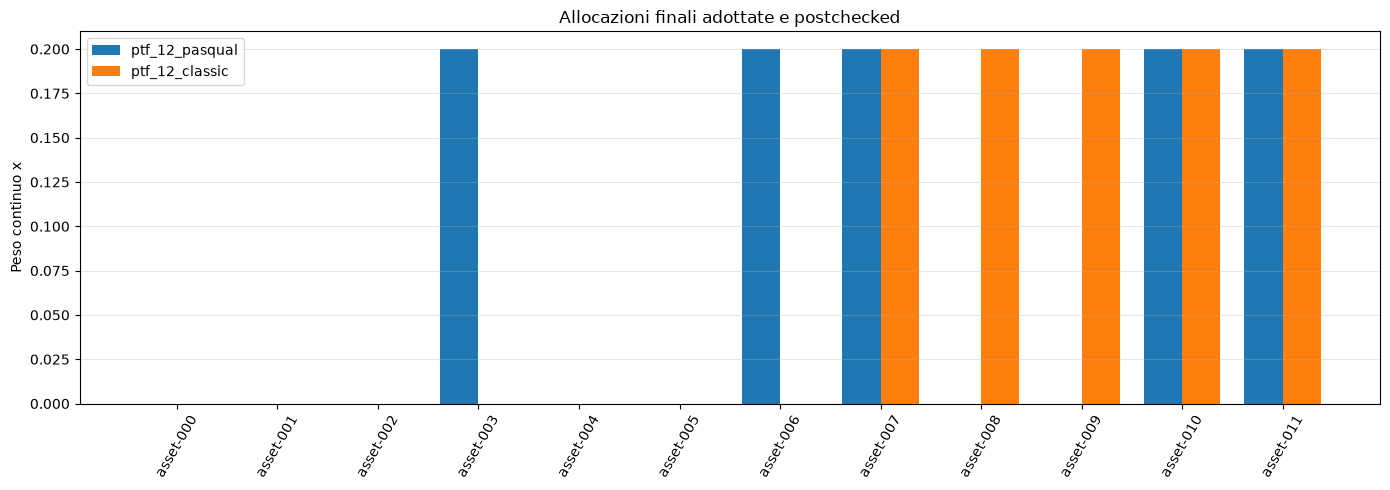

In [18]:
display(pd.DataFrame(comparison_summary(view, baseline)))
plot_allocations(view, baseline)
plt.show()


## 9. Interpretazione e limiti

- Distinguere congruenza geometrica, validità dei campioni e qualità MWIS.
- Separare esclusioni MWIS da esclusioni per cap e dalle allocazioni zero.
- Le metriche assenti negli artefatti storici rimangono non disponibili.
- Questo notebook non ottimizza rampe e non rilancia il benchmark classico:
  visualizza i risultati realmente registrati.
